# AA · Mathematical and Python prerequisites

Statistics becomes easier when its notation points to familiar operations. This reference develops the probability, algebra, calculus, and array operations used in the course. Read Sections 1–4 before the first inference chapters, and return to Sections 5–8 when working through regression. Calculus is useful for understanding the derivations but is not required to run the early notebooks.

```mermaid
flowchart LR
    A[Arithmetic and notation] --> B[Probability and conditioning]
    B --> C[Expectation and variability]
    C --> D[Sampling distributions]
    A --> E[Derivatives and chain rule]
    E --> F[Least squares derivation]
    F --> G[Matrix models and fit measures]
    D --> H[Reproducible Python calculations]
    G --> H
```

**Learning route:** translate notation → distinguish probability questions → differentiate a loss → solve a regression → verify the result in Python. This is a reference chapter, so each section points back to its use in the main course.

## 1. Sums, products, powers, and logarithms

For observations $x_1,\ldots,x_n$, a subscript identifies an observation. The notation $\sum_{i=1}^n x_i$ means add the observations; $\prod_{i=1}^n x_i$ means multiply them. Parentheses change what is being squared:

$$\sum_i x_i^2\ne\left(\sum_i x_i\right)^2\quad\text{in general}.$$

For $x=(1,2,4)$, these are 21 and 49. Similarly, $\sum_i(x_i-\bar x)^2$ is a sum of squared deviations; $[\sum_i(x_i-\bar x)]^2$ is zero because the deviations sum to zero. Squaring after summing would lose the spread entirely.

For nonnegative integers, $n!=n(n-1)\cdots1$ and $0!=1$. The binomial coefficient $\binom nk=n!/[k!(n-k)!]$ counts unordered subsets of size $k$. Choosing two of five objects gives ten subsets. Counting arrangements instead would count each pair twice.

The natural logarithm $\log$ is the inverse of the exponential $e^x$. For positive $a,b$, $\log(ab)=\log a+\log b$ and $\log(a/b)=\log a-\log b$. There is no corresponding rule $\log(a+b)=\log a+\log b$.

These rules explain log-likelihood: a product of positive likelihood contributions becomes a sum of log contributions. Because log is increasing, the maximizer stays the same. Adding raw densities instead of multiplying them generally changes the estimation problem. Software's `logpdf` and `logpmf` also avoid taking logs after tiny probabilities have already rounded to zero.

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / 'AA_Prerequisite' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


In [2]:
from math import comb
x = np.array([1,2,4.])
assert np.isclose(np.sum(x**2),21) and np.isclose(x.sum()**2,49)
assert np.isclose(np.sum(x-x.mean()),0)
print("Sum of squares:",np.sum(x**2),"; square of sum:",x.sum()**2)
print("Choose two of five:",comb(5,2))
contributions = np.array([.2,.4,.1])
assert np.isclose(np.log(contributions.prod()),np.log(contributions).sum())
print("Product:",contributions.prod(),"; log product:",np.log(contributions).sum())

Sum of squares: 21.0 ; square of sum: 49.0
Choose two of five: 10
Product: 0.008000000000000002 ; log product: -4.828313737302301


In Python, exponentiation is `**`; `^` is not exponentiation. Arrays support elementwise operations: `x**2` squares every entry, whereas `x.sum()**2` squares their sum.

## 2. Probability rules and conditioning

An **event** is a set of possible outcomes. Probabilities are nonnegative, total probability is one, and probabilities of disjoint events add. For general events,

$$P(A\cup B)=P(A)+P(B)-P(A\cap B).$$

The intersection appears twice in the two separate probabilities, so subtract it once. The complement rule is $P(A^c)=1-P(A)$. For $P(B)>0$, conditional probability is

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}.$$

Conditioning changes the reference set to cases where $B$ occurred. It is not generally symmetric: $P(A\mid B)$ and $P(B\mid A)$ can be very different.

Events are **independent** when $P(A\cap B)=P(A)P(B)$. If both have positive probability, this is equivalent to learning one event does not change the probability of the other. In contrast, mutually exclusive positive-probability events cannot occur together and are therefore dependent. Independence is a property to justify from a model or design, not an automatic multiplication rule for arbitrary events.

### An original sensor example: reverse a conditional probability

Suppose 10% of manufactured parts have a surface flaw. A screening sensor flags 90% of flawed parts and 20% of unflawed parts. What fraction of flagged parts are flawed?

Imagine 1,000 parts: about 100 are flawed and 900 unflawed. The flag counts are $100(0.9)=90$ and $900(0.2)=180$. Therefore only $90/(90+180)=1/3$ of flagged parts are flawed. The sensor's 90% detection probability is not the answer to the reverse question.

Formally, with $D$ for flaw and $F$ for flag, the law of total probability gives

$$P(F)=P(F\mid D)P(D)+P(F\mid D^c)P(D^c)=0.27.$$

Bayes' rule then gives

$$P(D\mid F)=\frac{P(F\mid D)P(D)}{P(F)}=\frac{0.09}{0.27}=\frac13.$$

![Composition of flags depends on the base rate as well as sensor performance](figure/conditional_probability.png)

P(flag): 0.27 ; P(flaw | flag): 0.33333333333333337


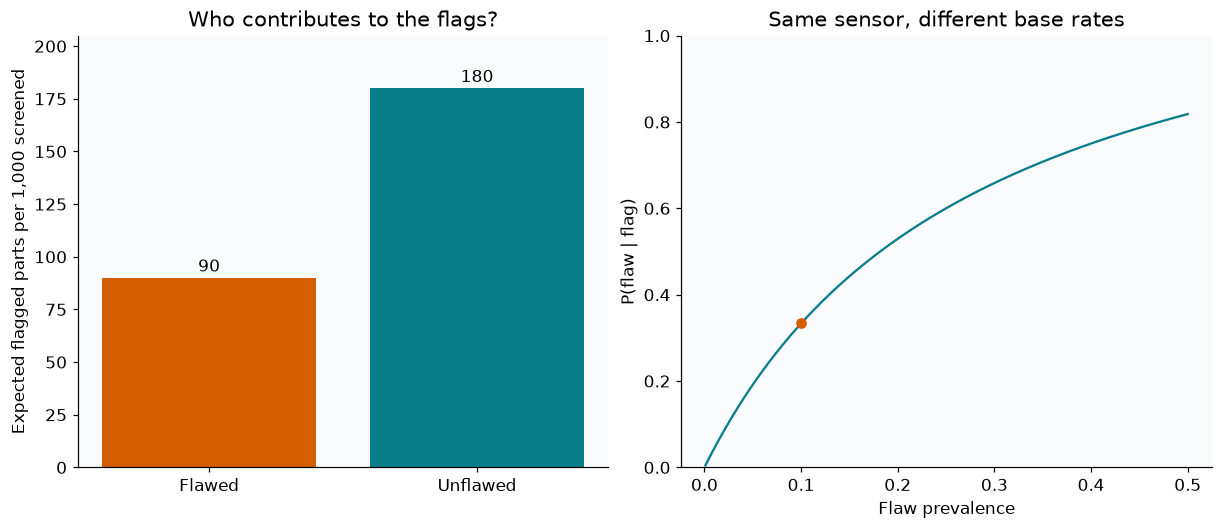

In [3]:
prevalence, detection, false_flag = .1,.9,.2
p_flag = detection*prevalence+false_flag*(1-prevalence)
posterior = detection*prevalence/p_flag
assert np.isclose(posterior,1/3)
print("P(flag):",p_flag,"; P(flaw | flag):",posterior)
fig, axes = plt.subplots(1,2,figsize=(11,4.7),layout="constrained")
axes[0].bar(["Flawed", "Unflawed"],[90,180],color=[ORANGE,TEAL])
axes[0].set(ylabel="Expected flagged parts per 1,000 screened",title="Who contributes to the flags?")
for i,count in enumerate([90,180]):
    axes[0].text(i,count+3,str(count),ha="center")
axes[0].set_ylim(0,205)
prior = np.linspace(.001,.5,300)
updated = detection*prior/(detection*prior+false_flag*(1-prior))
axes[1].plot(prior,updated,color=TEAL)
axes[1].scatter([prevalence],[posterior],color=ORANGE,zorder=3)
axes[1].set(xlabel="Flaw prevalence",ylabel="P(flaw | flag)",title="Same sensor, different base rates",ylim=(0,1))
save_figure(fig,"conditional_probability")

This example reverses a conditional probability because all required probabilities are specified. A p-value alone does not provide the ingredients for $P(H_0\mid\text{data})$; that inference requires a different model with appropriate prior probabilities and likelihoods.

## 3. Expectation, variance, and covariance

For a discrete random variable, $E[X]=\sum_x xP(X=x)$ when the sum is well defined. For a continuous variable with density $f$, replace the sum by $\int x f(x)\,dx$. Expectation is a probability-weighted average across possible outcomes, not necessarily a value that can occur in one observation.

With finite second moments,

$$\operatorname{Var}(X)=E[(X-E[X])^2]=E[X^2]-E[X]^2,$$

$$\operatorname{Cov}(X,Y)=E[(X-E[X])(Y-E[Y])].$$

Expectation is linear whether or not the variables are independent:

$$E[aX+bY+c]=aE[X]+bE[Y]+c.$$

Variance is different:

$$\operatorname{Var}(aX+bY)=a^2\operatorname{Var}(X)+b^2\operatorname{Var}(Y)+2ab\operatorname{Cov}(X,Y).$$

Independence implies zero covariance when the moments exist; zero covariance does not generally imply independence. For example, if $X$ is uniform on $[-1,1]$ and $Y=X^2$, covariance is zero by symmetry but $Y$ is completely determined by $X$.

For independent identically distributed observations with variance $\sigma^2$,

$$\operatorname{Var}(\bar X)=\frac{1}{n^2}\sum_i\operatorname{Var}(X_i)=\frac{\sigma^2}{n}.$$

Taking the square root gives $SE(\bar X)=\sigma/\sqrt n$. Correlated observations add covariance terms, so simply counting all rows as independent can badly understate uncertainty. This is why pairing and clustering affect inference.

## 4. The law of large numbers and the central limit theorem

The **law of large numbers** says that, under suitable assumptions such as independent identically distributed observations with finite absolute expectation, the sample mean converges in probability to the population mean. It describes where the mean goes as sample size grows.

The classical **central limit theorem** assumes independent identically distributed observations with finite, nonzero variance and describes the *shape and scale* of its error:

$$\frac{\sqrt n(\bar X-\mu)}{\sigma}\xrightarrow{d}N(0,1).$$

These are different statements. Neither says that the raw observations become normal. There is no universally adequate sample size of 30: convergence depends on features such as skewness, tails, dependence, and which probability is being approximated.

The notebook repeatedly samples exponential waiting times with mean and SD both 2. Each raw sample remains skewed, while standardized means become closer to normal as $n$ increases. The simulation uses the **known population SD** to demonstrate the theorem; replacing it by a sample estimate introduces another statistical step.

![The distribution of standardized means changes with sample size](figure/central_limit_theorem.png)

n=1: mean=-0.001, SD=0.997
n=5: mean=-0.008, SD=0.995
n=40: mean=-0.010, SD=0.995


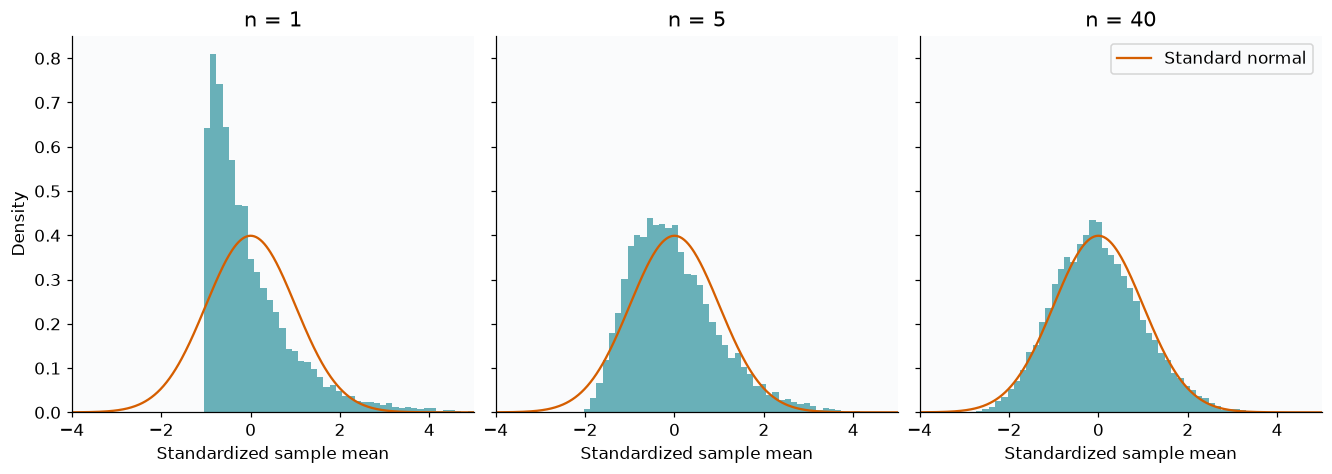

In [4]:
rng = np.random.default_rng(1201)
B, mu, sigma = 12000,2,2
fig, axes = plt.subplots(1,3,figsize=(12,4.2),layout="constrained",sharex=True,sharey=True)
grid = np.linspace(-4,5,400)
for ax,n in zip(axes,[1,5,40]):
    draws = rng.exponential(scale=mu,size=(B,n))
    standardized = np.sqrt(n)*(draws.mean(axis=1)-mu)/sigma
    ax.hist(standardized,bins=np.linspace(-4,5,65),density=True,color=TEAL,alpha=.6)
    ax.plot(grid,stats.norm.pdf(grid),color=ORANGE,label="Standard normal")
    ax.set(xlabel="Standardized sample mean",title=f"n = {n}",xlim=(-4,5))
    print(f"n={n}: mean={standardized.mean():.3f}, SD={standardized.std(ddof=1):.3f}")
axes[0].set_ylabel("Density")
axes[-1].legend()
save_figure(fig,"central_limit_theorem")

## 5. Derivatives: measuring a local rate of change

The derivative of $f$ at $x$ is the limit

$$f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h},$$

when it exists. It describes the slope of the tangent, not the average slope across an arbitrary large interval. The power rule gives $d(x^r)/dx=rx^{r-1}$ wherever the expression and derivative are defined. Constants differentiate to zero and derivatives distribute over sums.

For a composite function, the **chain rule** gives

$$\frac{d}{dx}f(g(x))=f'(g(x))g'(x).$$

For example, differentiating $L(b)=(5-2b)^2$ requires both the outside square and the inside linear function:

$$L'(b)=2(5-2b)(-2)=8b-20.$$

The stationary point is $b=2.5$. The second derivative is 8, so this quadratic is strictly convex and the point is its unique minimum. A zero derivative alone need not identify a minimum for an arbitrary function; it can also indicate a maximum or a stationary inflection point.

![The loss reaches its minimum where its derivative crosses zero](figure/derivative_and_loss.png)

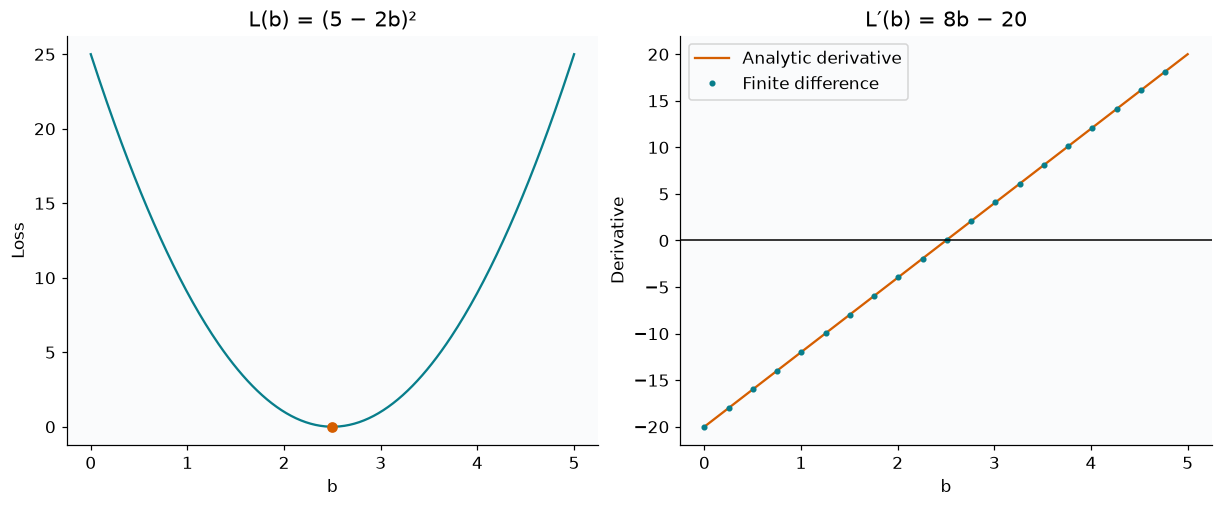

In [5]:
b = np.linspace(0,5,300)
loss = (5-2*b)**2
derivative = 8*b-20
step = 1e-5
finite_difference = ((5-2*(b+step))**2-(5-2*(b-step))**2)/(2*step)
assert np.allclose(finite_difference,derivative,atol=1e-7)
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
axes[0].plot(b,loss,color=TEAL)
axes[0].scatter([2.5],[0],color=ORANGE,zorder=3)
axes[0].set(xlabel="b",ylabel="Loss",title="L(b) = (5 − 2b)²")
axes[1].plot(b,derivative,color=ORANGE,label="Analytic derivative")
axes[1].plot(b[::15],finite_difference[::15],"o",ms=3,color=TEAL,label="Finite difference")
axes[1].axhline(0,color="black",lw=1)
axes[1].set(xlabel="b",ylabel="Derivative",title="L′(b) = 8b − 20")
axes[1].legend()
save_figure(fig,"derivative_and_loss")

A finite difference approximates the derivative numerically. Very large steps introduce approximation error; extremely small steps can lose precision through cancellation. It is useful for checking a derivation, but it is not the definition of an exact computer-generated answer.

## 6. Deriving the least-squares line

For a line with intercept $a$ and slope $b$, define

$$RSS(a,b)=\sum_{i=1}^n(y_i-a-bx_i)^2.$$

A **partial derivative** varies one coefficient while holding the other fixed. By the chain rule,

$$\frac{\partial RSS}{\partial a}=-2\sum_i(y_i-a-bx_i),\qquad
\frac{\partial RSS}{\partial b}=-2\sum_i x_i(y_i-a-bx_i).$$

Set both to zero. The first equation implies $\hat a=\bar y-\hat b\bar x$. Substitute this into the second and center the predictor:

$$\sum_i(x_i-\bar x)(y_i-\bar y)-\hat b\sum_i(x_i-\bar x)^2=0.$$

Thus, when $S_{xx}=\sum_i(x_i-\bar x)^2>0$,

$$\hat b=\frac{S_{xy}}{S_{xx}},\qquad \hat a=\bar y-\hat b\bar x.$$

If every $x_i$ is the same, $S_{xx}=0$: the data cannot identify separate intercept and slope effects. Otherwise the quadratic loss has a unique coefficient minimum. The residual equations also show that residuals sum to zero and are orthogonal to the predictor on the training data. These properties follow from fitting with an intercept; they are not evidence that the statistical assumptions hold.

For $x=(0,1,2,3)$ and $y=(1,2,2,4)$, $\bar x=1.5$, $\bar y=2.25$, $S_{xx}=5$, and $S_{xy}=4.5$. The fitted line is $\hat y=0.9+0.9x$, with residuals $(0.1,0.2,-0.7,0.4)$ and RSS 0.7.

![The least-squares coefficient pair lies at the bottom of the RSS contours](figure/least_squares_surface.png)

Coefficients: [0.9 0.9] ; residuals: [ 0.1  0.2 -0.7  0.4]
RSS: 0.7000000000000002 ; R²: 0.8526315789473684 ; adjusted R²: 0.7789473684210526


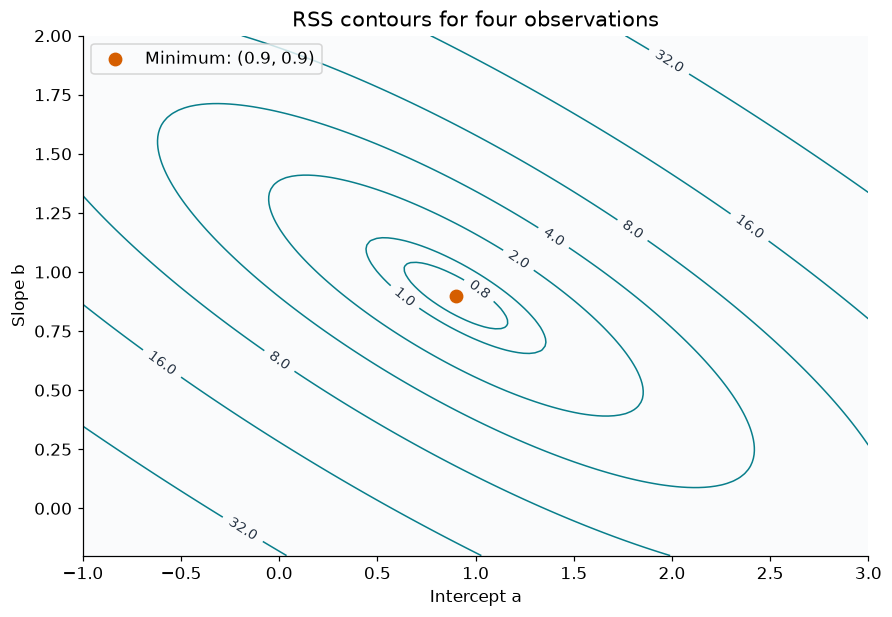

In [6]:
x = np.arange(4,dtype=float)
y = np.array([1,2,2,4.])
sxx = np.sum((x-x.mean())**2)
sxy = np.sum((x-x.mean())*(y-y.mean()))
slope = sxy/sxx
intercept = y.mean()-slope*x.mean()
X = np.column_stack([np.ones(len(x)),x])
beta,residual_sum,rank,singular_values = np.linalg.lstsq(X,y,rcond=None)
residuals = y-X@beta
rss = residuals@residuals
tss = np.sum((y-y.mean())**2)
assert np.allclose(beta,[intercept,slope]) and np.allclose(beta,[.9,.9])
assert np.isclose(rss,.7) and np.isclose(tss,4.75)
assert np.allclose(X.T@residuals,0,atol=1e-12) and rank==2
print("Coefficients:",beta,"; residuals:",residuals)
print("RSS:",rss,"; R²:",1-rss/tss,"; adjusted R²:",1-(rss/2)/(tss/3))
a_grid,b_grid = np.meshgrid(np.linspace(-1,3,140),np.linspace(-.2,2,140))
surface = np.sum((y[:,None,None]-a_grid[None,:,:]-x[:,None,None]*b_grid[None,:,:])**2,axis=0)
fig, ax = plt.subplots(figsize=(8,5.5),layout="constrained")
contours = ax.contour(a_grid,b_grid,surface,levels=[.8,1,2,4,8,16,32],colors=TEAL,linewidths=1)
ax.clabel(contours,inline=True,fontsize=9,colors="#273444")
ax.scatter([intercept],[slope],color=ORANGE,s=65,label="Minimum: (0.9, 0.9)",zorder=3)
ax.set(xlabel="Intercept a",ylabel="Slope b",title="RSS contours for four observations")
ax.legend()
save_figure(fig,"least_squares_surface")

## 7. Matrix notation and identifiability

Stack the data into $\mathbf y=X\boldsymbol\beta+\boldsymbol\varepsilon$. For a single predictor, each row of $X$ is $(1,x_i)$ and $\boldsymbol\beta=(a,b)^\top$. For multiple predictors, add columns. If $X$ has $K$ columns and full column rank,

$$\hat{\boldsymbol\beta}=(X^\top X)^{-1}X^\top\mathbf y.$$

This formula is valuable for understanding the normal equations $X^\top(\mathbf y-X\hat{\boldsymbol\beta})=0$. For computation, use a least-squares solver such as `np.linalg.lstsq` rather than explicitly forming an inverse. Such solvers handle numerical conditioning more carefully. A rank-deficient matrix does not identify a unique coefficient vector, even if a solver returns one representative solution.

An intercept plus one indicator for **every** category is redundant because the indicators sum to the intercept. Use a reference category or another full-rank coding. For ordinary residual variance estimation, also require $n>K$: full rank alone does not leave positive residual degrees of freedom.

## 8. RSS, MSE, and the denominator trap

Let $TSS=\sum_i(y_i-\bar y)^2>0$. For an intercept-containing OLS model,

$$R^2=1-\frac{RSS}{TSS}.$$

If both model losses are divided by the same $n$, then

$$1-\frac{RSS/n}{TSS/n}=R^2.$$

But $RSS/(n-K)$ estimates the error variance, and $TSS/(n-1)$ estimates the outcome variance. Using these different denominators produces **adjusted** $R^2$:

$$\bar R^2=1-\frac{RSS/(n-K)}{TSS/(n-1)}.$$

In the four-point example, $TSS=4.75$. Ordinary $R^2=1-0.7/4.75\approx0.8526$, while adjusted $R^2=1-(0.7/2)/(4.75/3)\approx0.7789$. A quantity called “MSE” must be read together with its denominator and purpose. On new data, prediction MSE estimates prediction performance and is not an unbiased estimate of the training error variance.

## 9. Working safely with arrays and reproducible experiments

The notebooks start with a shared setup cell and use local seeded generators such as `np.random.default_rng(123)`. The seed makes a calculation repeatable; it does not validate the model. Explicit seeds and pinned package versions make comparisons easier, though bit-for-bit outputs are not guaranteed across every numerical library and platform.

For an array with shape `(experiments, observations)`, `mean(axis=1)` computes one mean per experiment. Omitting `axis` averages everything into one number and can silently change the question. NumPy's `var` and `std` default to `ddof=0`; use `ddof=1` for the usual sample variance and SD. pandas column summaries may have different defaults, so choose deliberately.

Inspect dimensions, units, missingness, and finite values before fitting. A `NaN` is not a zero, and silently removing rows can make nested models use different samples. Every notebook here uses complete synthetic data to isolate the teaching point. For actual datasets, justify missing-data handling and verify that model comparisons use exactly the same observations.

Restart the kernel and run all cells in order. Variables left over from an earlier experiment can make an out-of-order notebook appear to work. The repository validation script executes each notebook in a fresh kernel and checks numerical identities as well as links and output files.

## 10. Practice

1. For $x=(2,3,5)$, calculate $\sum x_i^2$, $(\sum x_i)^2$, and $\sum(x_i-\bar x)$.
2. Change the flaw prevalence in the sensor example to 1%, keeping detection and false-flag rates unchanged. Find $P(D\mid F)$.
3. Differentiate $(7-3b)^2$ and find its minimum.
4. For $x=(0,1,2)$ and $y=(2,3,5)$, calculate the least-squares intercept, slope, RSS, and $R^2$.
5. What does `samples.mean(axis=1)` return if `samples.shape == (1000, 20)`? Why is its SD different from the SD of all 20,000 values?
6. If two variables have variances 4 and 9 and covariance 3, find the variance of their difference. What would an independence assumption change?

## 11. Worked answers

1. $4+9+25=38$; $(2+3+5)^2=100$; and zero, up to floating-point rounding in code.
2. $P(D\mid F)=0.9(0.01)/[0.9(0.01)+0.2(0.99)]=0.009/0.207\approx0.04348$. The same sensor has a much smaller fraction of true flaws among its flags when flaws are rare.
3. $-6(7-3b)=18b-42$. Set it to zero: $b=7/3$. The second derivative is 18, so the stationary point is the unique minimum.
4. $\bar x=1$, $\bar y=10/3$, $S_{xx}=2$, and $S_{xy}=3$. Hence $\hat b=1.5$, $\hat a=11/6$, RSS $=1/6$, $TSS=14/3$, and $R^2=27/28\approx0.9643$.
5. It returns 1,000 means, each computed from 20 observations. Under independent identically distributed sampling, their population SD is the original SD divided by $\sqrt{20}$; it measures variability of a mean rather than an individual observation.
6. $4+9-2(3)=7$. Assuming independence would incorrectly remove the covariance term and yield 13. Use the actual dependence structure.

In [7]:
rare_prior = .01
print("Practice 2:",.9*rare_prior/(.9*rare_prior+.2*(1-rare_prior)))
px = np.array([0,1,2.])
py = np.array([2,3,5.])
pX = np.column_stack([np.ones(3),px])
pbeta = np.linalg.lstsq(pX,py,rcond=None)[0]
prss = np.sum((py-pX@pbeta)**2)
ptss = np.sum((py-py.mean())**2)
assert np.allclose(pbeta,[11/6,1.5]) and np.isclose(prss,1/6)
assert np.isclose(1-prss/ptss,27/28)
print("Practice 4 coefficients:",pbeta,"; RSS:",prss,"; R²:",1-prss/ptss)
assert np.isclose(4+9-2*3,7)

Practice 2: 0.043478260869565216
Practice 4 coefficients: [1.83333333 1.5       ] ; RSS: 0.16666666666666669 ; R²: 0.9642857142857143


## References and next step

Reading connection: Starmer (2026), Appendices A–F, [SQ](../Reference.md#sq-statquest). The probability and least-squares derivations are standard results expressed here with original examples. Computational reference: [NumPy least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html); statistical background: [NIST least squares](https://www.itl.nist.gov/div898/handbook/pmd/section1/pmd141.htm). The matrix, covariance, and central-limit material extends the source appendices.

Return to [00 · Introduction](../00_Intro/00_Intro.md) or the [course map](../README.md).